# Defining the Game: Tic-Tac-Toe

## The Search Problem

A general search problem is defined in the following way:

* **Initial State:** Empty $3 \times 3$ board. It is the move for $x$.
* **Actions:** Place your symbol on any empty square.
* **Transition function:** You symbol is placed on the board according to the action. The opponent
    places her symbol. From our viewpoint this makes the environment non-deterministic.
* **Goal state:** A win (three symbols in a row, column or diagonal).
* **Path cost:** number of moves.
  
Since Tic-tac-toe is a game, we will use the more specializes components (see Chapter 5):
* `Actions(s)` Legal moves in state s.
* `Result(s, a)` Transition model.
* `Terminal(s)` Test for terminal states.
* `Utility(s)` Utility for player Max for terminal states.

**Notes:**

* To define the goal state we will use a test for a **terminal state** (game is over) and a **utility function** (win or loose).
* We will use DFS which is not optimal. So will probably not find the solution with the lowest path cost, i.e., win with the smallest number of moves. Therefore, we drop the path cost all together.

## Problem Size

### State Space Estimates

Each state is a possible board. Each of the 9 squares can have 3 values (empty, x and o), but some boards are impossible (where a player has several sequences of 3).The number of states in the state space graph is less than $3^9$.

In [ ]:
3**9

19683

A tighter bound for the search space size would be looking at all the ways we can choose $i = 1,2,3,...,9$ places from the board given by ${9 \choose i}$. Now we need to find all ways how we can choose half the symbols for player o which is given by ${i \choose \lfloor \frac{i}{2} \rfloor}$.
Put together we get $\sum_{i=1}^9{{9 \choose i}{i \choose \lfloor \frac{i}{2} \rfloor}}$.

In [2]:
import math

print("level\tboards")
sum = 0

for i in range(1,9):
    sum += math.comb(9, i) * math.comb(i, math.floor(i/2))
    print(i, "\t", math.comb(9, i) , " x ", math.comb(i, math.floor(i/2)) , " = ",  math.comb(9, i) * math.comb(i, math.floor(i/2)))

sum

level	boards
1 	 9  x  1  =  9
2 	 36  x  2  =  72
3 	 84  x  3  =  252
4 	 126  x  6  =  756
5 	 126  x  10  =  1260
6 	 84  x  20  =  1680
7 	 36  x  35  =  1260
8 	 9  x  70  =  630


5919

This is an upper bound since it contains some infeasible boards where both players have 3 in a row.

### Space and Time Complexity Using the Search Tree Estimates

For solving the problem, we use the search tree which can be significantly larger than the state space.
A search tree is a subgraph with all **cycles removed.** The standard implementation of DFS **cannot remove redundant paths** (i.e., getting to the same board by plcing symbols in a different order). Therefore, a state can be represented by several nodes in different branches! We observe the following:

* The complete search tree has a maximal depth $m=9$
* The max branching factor $b=9$ (for first move).

DFS has

* a space complexity of $O(bm)$ (current path plus frontier) and
* a time complecity of $O(b^m)$ (number of expanded nodes).

In [ ]:
# Space Complexity O(bm):
9*9

81

In [ ]:
# Time Complexity O(b^m):
9**9

387420489

The branching factor decreases after each move. The first level has a branching factor of 9, the second a branching factor of 8, etc. The total number of nodes is:

| <div style="width:100px">Level</div>      |  <div style="width:200px"># of nodes</div>   |
| :------------- | :---------------- |
| root       | $1$ |
| level 1    | $9 = 9!/8!$ |
| level 2    | $9 \times 8 = 9!/7!$ |
| level 2    | $9 \times 8 \times 7 = 9!/6!$ |
| ...        |  ... |
| level 9    | $9 \times 8 \times \dots \times 2 \times 1 = 9!$ |

The total number of game tree nodes is less (some games end early) than the sum of the nodes above. The upper bound for the number of nodes is

$\sum_{i = 0}^9 \frac{9!}{i!}$

In [3]:
sum = 1
partial_fac = 1
print("level\t# nodes")
print("root\t 1")

for i in range(9, 0, -1):
    partial_fac *= i
    sum += partial_fac
    print(10-i, "\t", partial_fac)

sum

level	# nodes
root	 1
1 	 9
2 	 72
3 	 504
4 	 3024
5 	 15120
6 	 60480
7 	 181440
8 	 362880
9 	 362880


986410

Since some sequences are cut short because of a win, we expect fewer nodes in the game complete tree.

**Redundant paths:** The tree size estimation contains redundant paths.

**Cycles:** Tic-tac-toe does not have cycles (you cannot remove a played symbol).


__Note:__ This size makes tic-tac-toe a very small problem that can be easily solved by tree search. Most games and real problems are too large and cannot be solved this way. For example, chess has an estimated state space size of $>10^{30}$.
We will learn several methods that address this problem later.

## Implementation

We need to implement the following functions:

* `Actions(s)` Legal moves in state s.
* `Result(s, a)` Transition model.
* `Terminal(s)` Test for terminal states.
* `Utility(s)` Utility for player Max for terminal states.

The state (a board position) will be implemented as a vector (in Python this is a list) of length 9. The values are `' ', 'x', 'o'`. The actions are just the index in the list (0, 1, 2, ..., 8).


The implementation of these and some other helper functions can be found in [tictactoe.py](tictactoe.py)
and be imported from that file

In [5]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [6]:
from tictactoe import empty_board, actions, result, terminal, utility
from tictactoe import show_board, show_board_text

## Examples

In [7]:
board = empty_board()
board[0] = 'x'; board[3] = 'x'; board[6] = 'x'; board[1] = 'o'; board[4] = 'o'
display(board)

['x', 'o', ' ', 'x', 'o', ' ', 'x', ' ', ' ']

In [8]:
show_board_text(board)

[['x' 'o' ' ']
 ['x' 'o' ' ']
 ['x' ' ' ' ']]


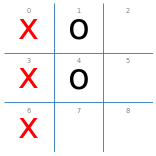

In [9]:
show_board(board)

In [10]:
actions(board)

[2, 5, 7, 8]

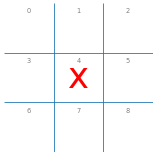

In [11]:
board2 = empty_board()
board2 = result(board2, 'x', 4)
show_board(board2)

In [12]:
print(terminal(board))
print(terminal(board2))

True
False


## Experiments


### Baseline: Randomized Player

A completely randomized player agent can be used as a weak baseline. A simple random agent and a the game environment
are implemented in [tictactoe.py](tictactoe.py) as `random_player()` and `play()`, respectively.

In [13]:
from tictactoe import random_player, play

### Random vs. Random

Let a random player play another random player for 100 games and look at the number of wins.

In [14]:
%time display(play(random_player, random_player, N = 100))

{'x': 49, 'o': 33, 'd': 18}

CPU times: user 57.3 ms, sys: 3.77 ms, total: 61.1 ms
Wall time: 64.5 ms


_Note:_ It looks like the first player (x) has an advantage!

**Hoàn thành yêu cầu bài thực hành**
1. Mô hình trò chơi
- Biểu diễn trạng thái: bàn cờ là một list gồm 9 phần tử, tương ứng 9 ô theo thứ tự hàng ngang từ trái sang phải, từ trên xuống dưới. Mỗi ô có giá trị ' ' (trống), 'x' hoặc 'o'.
- Hành động hợp lệ – actions(state): trả về danh sách chỉ số của các ô còn trống. Mỗi hành động là một số nguyên từ 0 đến 8.
- Chuyển trạng thái – result(state, player, action): kiểm tra ô được chọn có trống không; nếu hợp lệ, sao chép trạng thái hiện tại, đặt ký hiệu của người chơi vào ô đó và trả về trạng thái mới. Hàm không tự đổi lượt.
- Trạng thái kết thúc – terminal(state): trả về True nếu X hoặc O đã có ba ký hiệu liên tiếp theo hàng, cột, đường chéo hoặc bàn cờ đã đầy và hòa; ngược lại trả về False. Hàm dựa vào check_board(state).
- Hàm lợi ích – utility(state, player='x'): xét từ góc nhìn của người chơi được truyền vào (mặc định là X): +1 nếu người đó thắng, 0 nếu hòa, -1 nếu thua và None nếu ván chưa kết thúc.
Sơ đồ chỉ số ô: 0 1 2 / 3 4 5 / 6 7 8. Người chơi X đi trước; sau đó hai người chơi lần lượt đánh vào một ô trống.

2. Thử các hàm và quan sát cách đánh số ô
Chạy cell dưới đây để kiểm tra trạng thái rỗng, danh sách hành động, chuyển trạng thái, trạng thái kết thúc và lợi ích. Bàn cờ mẫu trong notebook gốc có X tại các ô 0, 3, 6 nên X đã thắng theo cột đầu tiên.

Bàn cờ ban đầu:


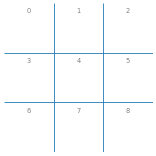

Các hành động hợp lệ: [0, 1, 2, 3, 4, 5, 6, 7, 8]
Sau khi X đánh vào ô 4:


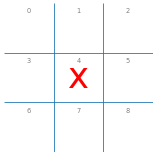

Bàn cờ cũ vẫn rỗng: [' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ']
Các ô còn trống: [0, 1, 2, 3, 5, 6, 7, 8]
Đã kết thúc chưa? False
Utility của X: None


In [15]:
# Kiểm tra các hàm trên bàn cờ rỗng
board = empty_board()
print("Bàn cờ ban đầu:")
show_board(board)
print("Các hành động hợp lệ:", actions(board))

# Thử đánh X vào ô số 4 (ô chính giữa)
board_after_x = result(board, 'x', 4)
print("Sau khi X đánh vào ô 4:")
show_board(board_after_x)
print("Bàn cờ cũ vẫn rỗng:", board)
print("Các ô còn trống:", actions(board_after_x))
print("Đã kết thúc chưa?", terminal(board_after_x))
print("Utility của X:", utility(board_after_x))


 X thắng


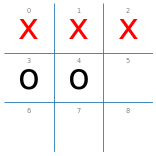

check_board: x
terminal: True
utility theo X: 1
utility theo O: -1

 O thắng


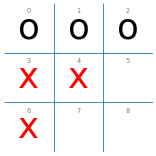

check_board: o
terminal: True
utility theo X: -1
utility theo O: 1

 Hòa


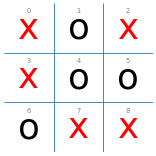

check_board: d
terminal: True
utility theo X: 0
utility theo O: 0

 Chưa kết thúc


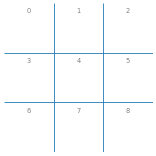

check_board: n
terminal: False
utility theo X: None
utility theo O: None


In [17]:
from tictactoe import check_board

# Kiểm tra các trường hợp X thắng, O thắng, hòa và chưa kết thúc
x_win = ['x', 'x', 'x', 'o', 'o', ' ', ' ', ' ', ' ']
o_win = ['o', 'o', 'o', 'x', 'x', ' ', 'x', ' ', ' ']
draw = ['x', 'o', 'x', 'x', 'o', 'o', 'o', 'x', 'x']
not_finished = empty_board()

for name, state in [("X thắng", x_win), ("O thắng", o_win), ("Hòa", draw), ("Chưa kết thúc", not_finished)]:
    print("\n", name)
    show_board(state)
    print("check_board:", check_board(state))
    print("terminal:", terminal(state))
    print("utility theo X:", utility(state, 'x'))
    print("utility theo O:", utility(state, 'o'))

**Nhận xét:** `check_board()` trả về x hoặc o khi phát hiện một hàng, cột hay đường chéo có ba ký hiệu giống nhau; trả về d khi bàn cờ đầy mà không ai thắng; và trả về n khi vẫn còn lượt chơi. Vì vậy `terminal()` chỉ trả về True cho ba trường hợp kết thúc đầu tiên. `utility()` không xác định giá trị cho trạng thái chưa kết thúc nên trả về None.

**3. Thực nghiệm: Random Player đấu với Random Player trong 1.000 ván**
Hai người chơi đều chọn ngẫu nhiên một ô còn trống. X luôn được đi trước. Đặt seed để có thể tái lập kết quả của lần chạy này.

In [18]:
import numpy as np
np.random.seed(42)
results = play(random_player, random_player, N=1000)
print("Kết quả sau 1.000 ván:")
print("X thắng:", results['x'])
print("O thắng:", results['o'])
print("Hòa:", results['d'])
print("Tổng:", results['x'] + results['o'] + results['d'])
print("Tỷ lệ (%):", {key: round(value / 10, 1) for key, value in results.items()})

Kết quả sau 1.000 ván:
X thắng: 590
O thắng: 284
Hòa: 126
Tổng: 1000
Tỷ lệ (%): {'x': 59.0, 'o': 28.4, 'd': 12.6}


**4. Nhận xét kết quả**

Với np.random.seed(42), lần chạy mẫu thu được 590 ván X thắng, 284 ván O thắng và 126 ván hòa (tương ứng 59,0%, 28,4% và 12,6%). Số ván X thắng cao hơn rõ rệt số ván O thắng. Điều này cho thấy trong thực nghiệm với hai người chơi chọn nước đi ngẫu nhiên, người đi trước (X) có lợi thế vì được đánh trước một lượt và có nhiều cơ hội tạo chuỗi ba ký hiệu trước đối thủ.

Lưu ý: đây là kết quả của một lần chạy có seed cố định; khi thay seed hoặc chạy lại mà không cố định seed, số liệu có thể thay đổi. Kết quả này phản ánh lợi thế quan sát được trong mô hình chơi ngẫu nhiên, không có nghĩa người đi trước luôn thắng trong mọi ván.